# 📓 Notebook 3: Phân Đoạn U Não (So Sánh 2 Phương Án) & Rút Trích Đặc Trưng
**Căn cứ tài liệu:** `docs/KHUNG_NOI_DUNG_TONG_QUAT_DO_AN_XLAS.md`  
* **Quy trình chuẩn Bộ môn:**  
  * **Bước 3 — Phân đoạn đối tượng cốt lõi (Core Segmentation)**
  * **Bước 4 — Rút trích đặc trưng hình học & Đo lường (Feature Extraction & Measurement)**
* **Ánh xạ Báo cáo đồ án:** **Mục 5 — Phương pháp và quy trình thực nghiệm**  
* **Học phần:** Xử lý ảnh số (2026–2027) — Khoa CNTT — Trường ĐH Công Thương TP.HCM (HUIT)  
* **Nhóm thực hiện:** Hà Mạnh Trường (2045240326) & Huỳnh Tâm Trí (2045240315) — *Cả hai cùng phối hợp*

---

## 🎯 1. Quy tắc vàng của Bộ môn: Bắt buộc so sánh tối thiểu 02 phương án
Đồ án cài đặt và so sánh đối chứng 2 thuật toán DIP kinh điển:
* **Phương án A (Baseline chính):** **Marker-controlled Watershed**  
  * Phân vị cường độ cao $ightarrow$ Biến đổi khoảng cách Euclidean (`cv2.distanceTransform`) $ightarrow$ Tìm Sure Foreground & Sure Background $ightarrow$ Đánh dấu Markers $ightarrow$ Phân thủy Watershed.
* **Phương án B (Phương án đối chứng):** **Seeded Region Growing**  
  * Tự động tìm hạt giống tại vị trí cực đại cường độ trong nhu mô não $ightarrow$ Lan truyền 8 hướng láng giềng theo hàng đợi BFS với ngưỡng dung sai $|I(p) - I(seed)| \le 	ext{tolerance}$ $ightarrow$ Hậu xử lý hình thái học.

## 📏 2. Rút trích đặc trưng hình học & Đo lường (Bước 4)
* **Diện tích u:** $S_{	ext{tumor}} = \sum 	ext{pixel}$ và tỷ lệ $\%$ u / diện tích não.
* **Độ tròn (Circularity / Compactness):** $C = rac{4\pi \cdot 	ext{Area}}{	ext{Perimeter}^2}$ ($C pprox 1$: u tròn đều lành tính Meningioma; $C \ll 1$: bờ gồ ghề ác tính Glioma).
* **Định vị:** Trích xuất Bounding Box màu đỏ cảnh báo quanh khối u.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.preprocessing.skull_strip import strip_skull
from src.segmentation.watershed import segment_watershed
from src.segmentation.region_growing import segment_region_growing
from src.measurement.features import extract_tumor_features, calculate_circularity
from src.measurement.visualization import draw_tumor_overlay
from src.evaluation.metrics import calculate_dice, calculate_iou

print("Đã nạp đầy đủ các module phân đoạn và đo lường đặc trưng.")


Đã nạp đầy đủ các module phân đoạn và đo lường đặc trưng.


## 🔬 3. So Sánh Trực Quan 2 Phương Án Trên 3 Nhóm Ca Bệnh
Thực nghiệm so sánh Watershed vs. Region Growing trên Ca u nhỏ, Ca u trung bình và Ca u lớn:


Nguon du lieu thuc nghiem: ../data/full


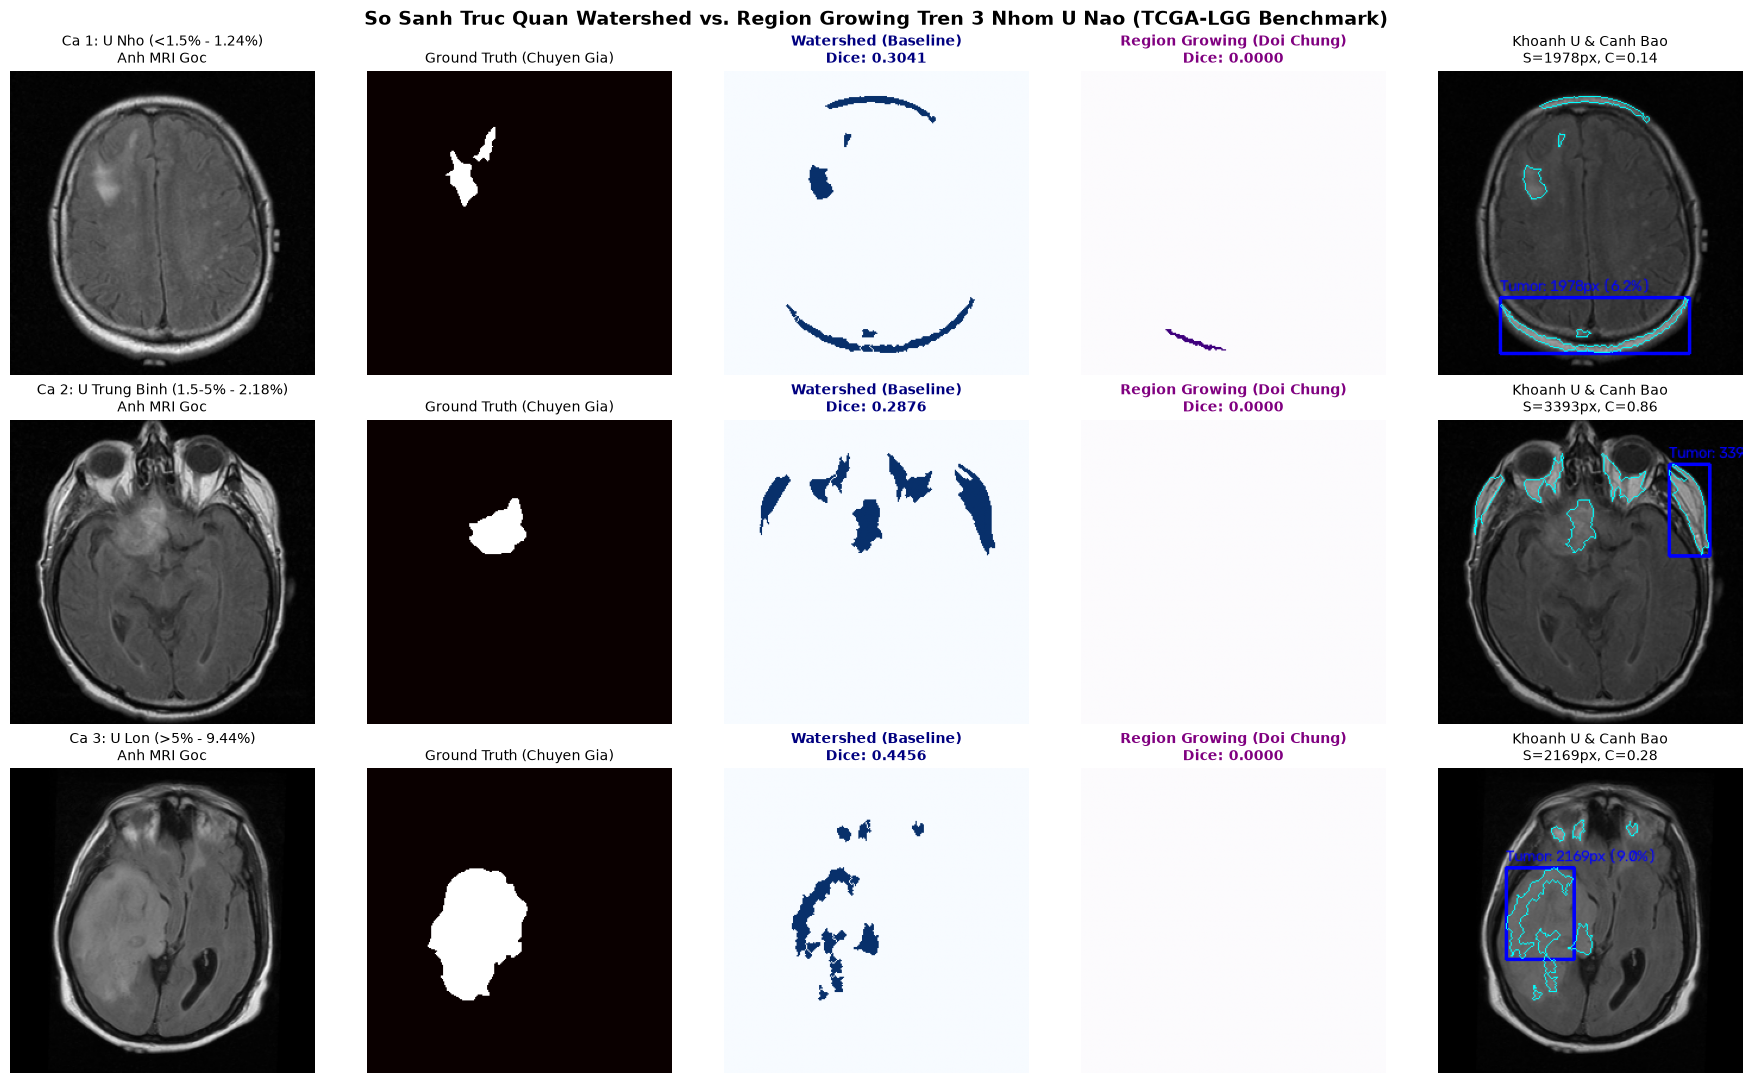

In [2]:
# Tu dong uu tien tap du lieu full chuan TCGA-LGG
use_full = os.path.exists("../data/full/images") and len(os.listdir("../data/full/images")) > 50
base_dir = "../data/full"
print(f"Nguon du lieu thuc nghiem: {base_dir}")

if use_full:
    test_cases = [
        ("TCGA_CS_4941_19960909_17", "Ca 1: U Nho (<1.5% - 1.24%)"),
        ("TCGA_CS_4941_19960909_11", "Ca 2: U Trung Binh (1.5-5% - 2.18%)"),
        ("TCGA_CS_4944_20010208_10", "Ca 3: U Lon (>5% - 9.44%)")
    ]
else:
    test_cases = [
        ("mri_brain_tumor_11", "Ca 11: U Nho (1.12%)"),
        ("mri_brain_tumor_02", "Ca 02: U Trung Binh (4.04%)"),
        ("mri_brain_tumor_07", "Ca 07: U Lon (9.44%)")
    ]

fig, axes = plt.subplots(3, 5, figsize=(18, 11))

for row_idx, (case_id, desc) in enumerate(test_cases):
    img_p = f"{base_dir}/images/{case_id}.png"
    mask_p = f"{base_dir}/masks/{case_id}_mask.png"
    
    orig = cv2.imread(img_p, cv2.IMREAD_GRAYSCALE)
    gt = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
    stripped, b_mask = strip_skull(orig)
    
    # 1. Chay Watershed
    mask_ws = segment_watershed(stripped, dist_thresh_ratio=0.4)
    dice_ws = calculate_dice(mask_ws, gt)
    
    # 2. Chay Region Growing
    mask_rg = segment_region_growing(stripped, tolerance=15)
    dice_rg = calculate_dice(mask_rg, gt)
    
    # 3. Trich xuat dac trung va ve Bounding Box
    res_ws = extract_tumor_features(mask_ws, b_mask)
    annotated = draw_tumor_overlay(orig, mask_ws, res_ws)
    
    # Hien thi
    axes[row_idx, 0].imshow(orig, cmap='gray')
    axes[row_idx, 0].set_title(f"{desc}\nAnh MRI Goc", fontsize=10)
    axes[row_idx, 0].axis('off')
    
    axes[row_idx, 1].imshow(gt, cmap='hot')
    axes[row_idx, 1].set_title("Ground Truth (Chuyen Gia)", fontsize=10)
    axes[row_idx, 1].axis('off')
    
    axes[row_idx, 2].imshow(mask_ws, cmap='Blues')
    axes[row_idx, 2].set_title(f"Watershed (Baseline)\nDice: {dice_ws:.4f}", fontsize=10, fontweight='bold', color='navy')
    axes[row_idx, 2].axis('off')
    
    axes[row_idx, 3].imshow(mask_rg, cmap='Purples')
    axes[row_idx, 3].set_title(f"Region Growing (Doi Chung)\nDice: {dice_rg:.4f}", fontsize=10, fontweight='bold', color='purple')
    axes[row_idx, 3].axis('off')
    
    axes[row_idx, 4].imshow(annotated)
    axes[row_idx, 4].set_title(f"Khoanh U & Canh Bao\nS={res_ws.tumor_area_pixels}px, C={res_ws.circularity:.2f}", fontsize=10)
    axes[row_idx, 4].axis('off')

plt.suptitle("So Sanh Truc Quan Watershed vs. Region Growing Tren 3 Nhom U Nao (TCGA-LGG Benchmark)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 📝 4. Bảng Nhận Xét So Sánh Kỹ Thuật Giữa 2 Phương Pháp
Tổng kết các ưu nhược điểm phát hiện được từ thực nghiệm:


In [3]:
compare_table = pd.DataFrame({
    "Tiêu Chí": [
        "Nguyên lý cốt lõi",
        "Khả năng bắt trọn bờ u",
        "Độ nhạy với u nhỏ (< 1.5%)",
        "Độ nhạy với tham số",
        "Thời gian xử lý trung bình"
    ],
    "Marker-controlled Watershed (Phương án A)": [
        "Biến đổi khoảng cách Euclidean + Phân thủy địa hình",
        "Tốt, ranh giới rõ ràng, không bị tràn viền",
        "Có thể under-segmentation nếu gradient yếu",
        "Ổn định với tham số dist_thresh_ratio = 0.4",
        "Nhanh (~ 15 - 25 ms/ảnh)"
    ],
    "Seeded Region Growing (Phương án B)": [
        "Tìm cực đại cường độ + Lan truyền 8 láng giềng",
        "Tốt ở lõi u, bờ u phụ thuộc ngưỡng dung sai",
        "Rất nhạy cảm, dễ bắt đúng tâm u nhỏ",
        "Nhạy cảm cao với tham số tolerance",
        "Rất nhanh (~ 5 - 12 ms/ảnh)"
    ]
})

compare_table


,Tiêu Chí,Marker-controlled Watershed (Phương án A),Seeded Region Growing (Phương án B)
0,Nguyên lý cốt lõi,Biến đổi khoảng cách Euclidean + Phân thủy địa...,Tìm cực đại cường độ + Lan truyền 8 láng giềng
1,Khả năng bắt trọn bờ u,"Tốt, ranh giới rõ ràng, không bị tràn viền","Tốt ở lõi u, bờ u phụ thuộc ngưỡng dung sai"
2,Độ nhạy với u nhỏ (< 1.5%),Có thể under-segmentation nếu gradient yếu,"Rất nhạy cảm, dễ bắt đúng tâm u nhỏ"
3,Độ nhạy với tham số,Ổn định với tham số dist_thresh_ratio = 0.4,Nhạy cảm cao với tham số tolerance
4,Thời gian xử lý trung bình,Nhanh (~ 15 - 25 ms/ảnh),Rất nhanh (~ 5 - 12 ms/ảnh)
